# Estudo de otimização de portfólio com computação clássica e quântica

## Portfólio ou Carteira de investimentos

É um conjunto de ativos financeiros que um investidor possui, com o objetivo de diversificar seus investimentos e reduzir riscos.

A composição do portfólio pode incluir:

- Ações
- Títulos de renda fixa
- Fundos de investimento

**Limitações do universo de ativos:** usamos apenas 4 ações escolhidas com base no histórico recente, o que introduz viés de sobrevivência. Dois dos quatro ativos são bancos, com correlação relevante entre si, o que reduz o ganho de diversificação. Os resultados valem para este universo, e não para o mercado como um todo.

In [63]:
import numpy as np
import pandas as pd
import yfinance as yfin
import matplotlib.pyplot as plt

## 1. Dados históricos

**Pergunta:** quanto cada ação valorizou ou desvalorizou no período?

In [64]:
ativos = ['ITUB4.SA', 'VALE3.SA', 'KLBN4.SA', 'BBAS3.SA'] # Itaú (ITUB4), Vale (VALE3), Klabin (KLBN4) e Banco do Brasil (BBAS3) -> cotação em Reais (R$)
dados_brutos = yfin.download(ativos, start="2023-01-01", end="2026-01-01")

# Cópia local dos dados para reprodutibilidade (E-16)
import os
os.makedirs('../data', exist_ok=True)
dados_brutos.to_csv('../data/precos_b3.csv')
dados_brutos.head()

[*********************100%***********************]  4 of 4 completed


Price           Close                                       High             \
Ticker       BBAS3.SA   ITUB4.SA  KLBN4.SA   VALE3.SA   BBAS3.SA   ITUB4.SA   
Date                                                                          
2023-01-02  13.151780  16.584929  2.902408  64.798630  13.531388  16.612017   
2023-01-03  12.906618  16.239555  2.916885  64.682663  13.207141  16.693286   
2023-01-04  13.072699  16.286957  2.953075  64.798630  13.151782  16.605246   
2023-01-05  13.669789  16.794874  2.974788  65.885864  13.737012  16.869368   
2023-01-06  13.859590  17.086073  2.945836  66.929604  13.946583  17.140249   

Price                                  Low                                  \
Ticker      KLBN4.SA   VALE3.SA   BBAS3.SA   ITUB4.SA  KLBN4.SA   VALE3.SA   
Date                                                                         
2023-01-02  2.931360  65.161038  13.009429  16.280184  2.858981  64.168037   
2023-01-03  2.938599  65.298756  12.819624  16.137973  2.873457  64.428978   
2023-01-04  2.996502  64.979834  12.874987  16.171831  2.916885  63.747642   
2023-01-05  3.003740  66.451221  13.080609  16.266649  2.924123  64.508711   
2023-01-06  2.996501  67.219532  13.618381  16.794871  2.924122  65.958351   

Price            Open                                    Volume            \
Ticker       BBAS3.SA   ITUB4.SA  KLBN4.SA   VALE3.SA  BBAS3.SA  ITUB4.SA   
Date                                                                        
2023-01-02  13.531388  16.544297  2.909646  64.276761  23557000  26445013   
2023-01-03  13.151780  16.584932  2.924123  64.798636  21547400  33847015   
2023-01-04  12.981751  16.293728  2.924123  64.726149  19519000  33855739   
2023-01-05  13.163648  16.320826  2.953075  64.842126  33937600  41153732   
2023-01-06  13.701421  16.882909  2.974787  65.958351  29504600  42632750   

Price                          
Ticker     KLBN4.SA  VALE3.SA  
Date                           
2023-01-02  1361863  12783800  
2023-01-03  1937361  25332600  
2023-01-04  2029908  26395300  
2023-01-05  1468408  29085600  
2023-01-06  2222888  31420600

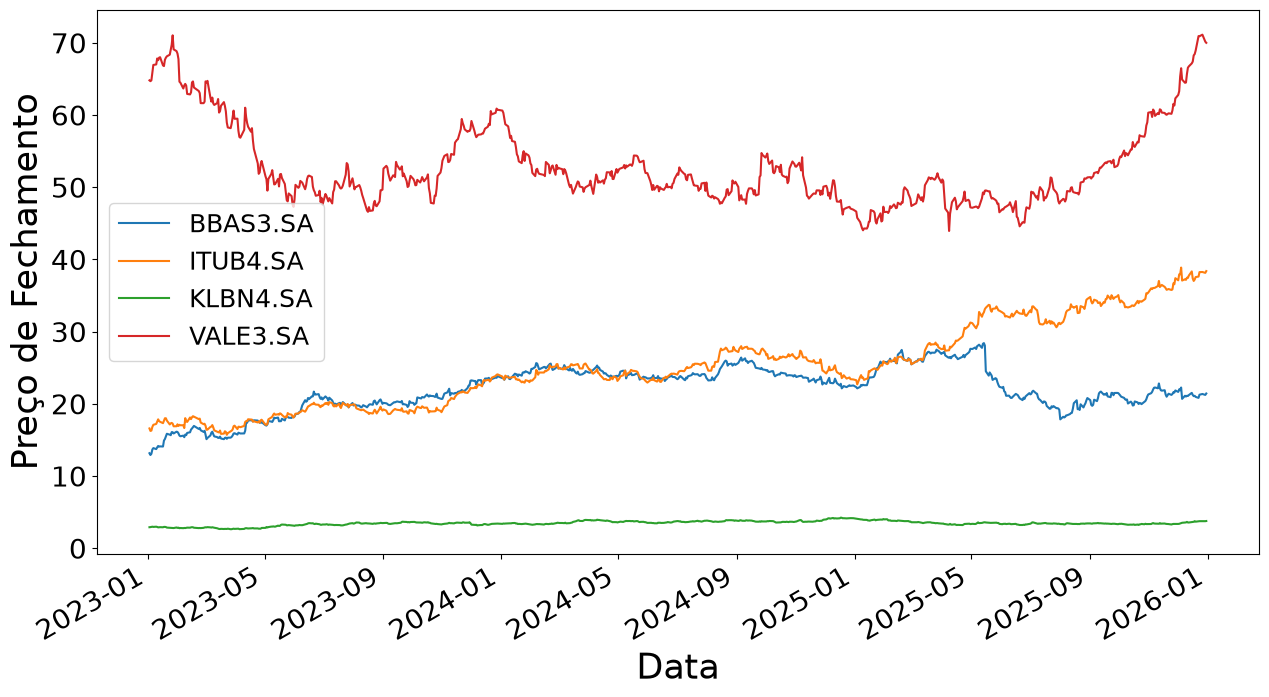

In [65]:
df = dados_brutos['Close']
ativos = list(df.columns)  # E-08: mesma ordem das colunas do yfinance (alfabética) 
#
df.plot(figsize=[15,8])
plt.xlabel('Data',  fontsize=25)
plt.ylabel('Preço de Fechamento',fontsize=25)
plt.xticks(fontsize=20)
plt.yticks(fontsize=20)
plt.legend(loc = 'best', fontsize=18);
plt.show()

## 2. Preços e retornos

**Pergunta:** como medir o quanto um ativo sobe ou cai por dia?

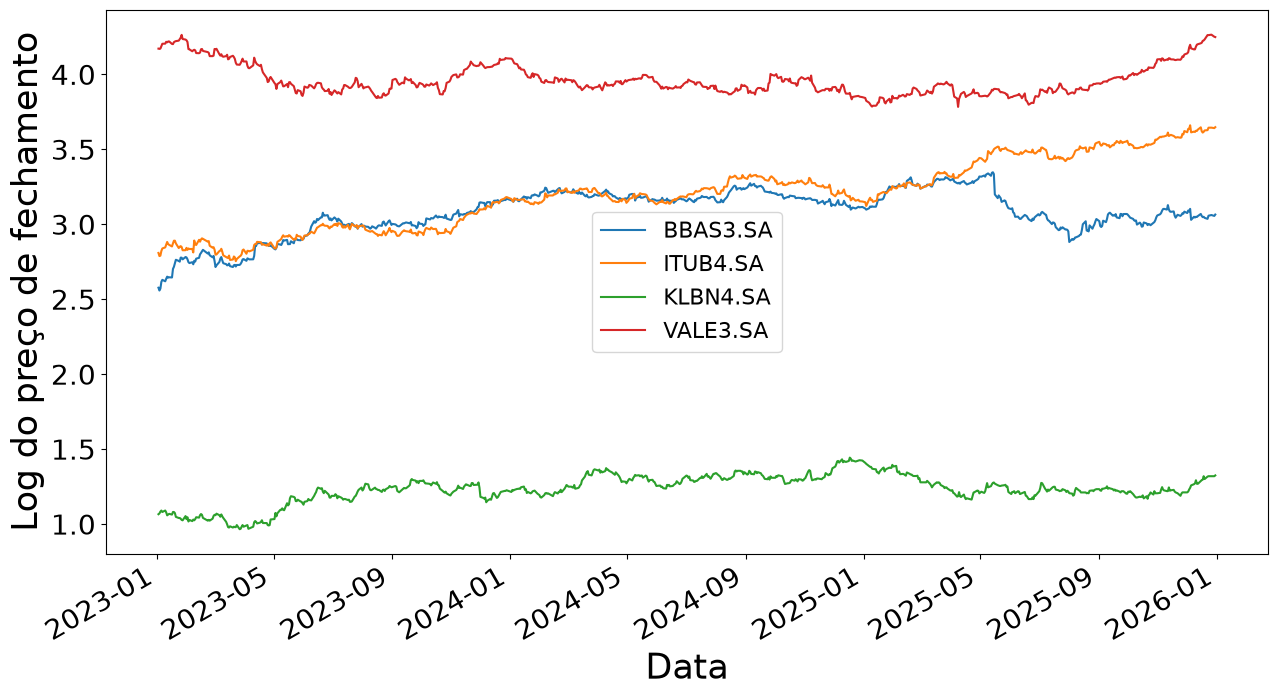

In [66]:
np.log(df).plot(figsize=(15, 8))

plt.xlabel('Data', fontsize=25)
plt.ylabel('Log do preço de fechamento', fontsize=25)
plt.xticks(fontsize=20)
plt.yticks(fontsize=20)
plt.legend(loc='best', fontsize=16)
plt.show()

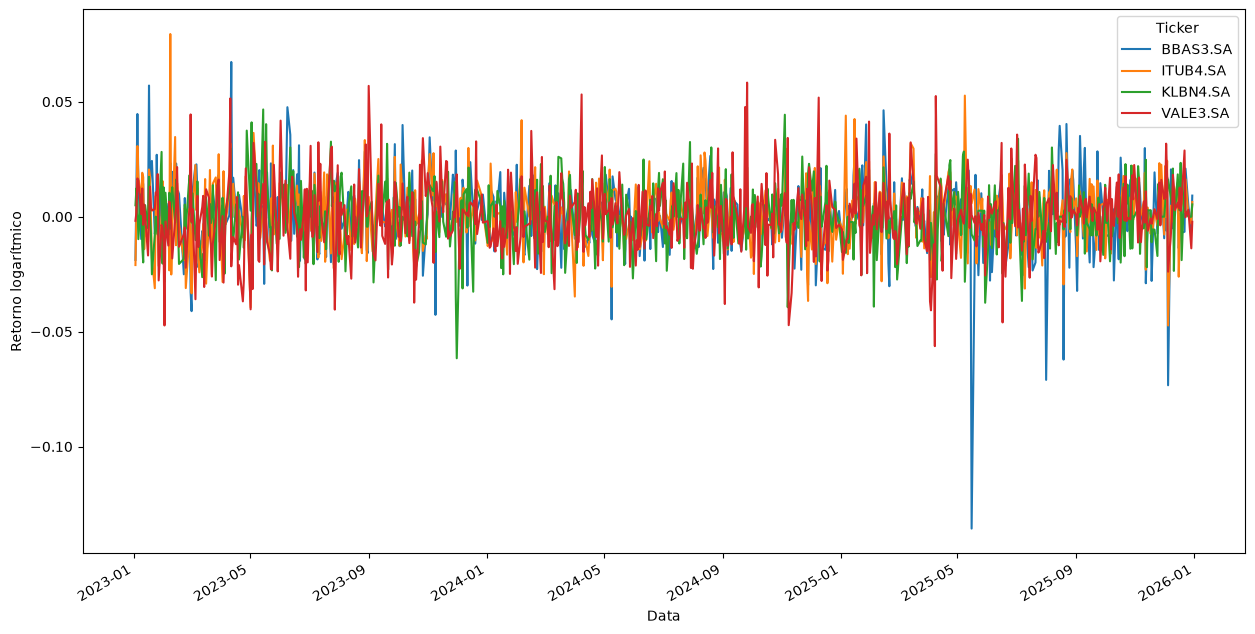

In [67]:
log_returns = np.log(df / df.shift(1))

log_returns.plot(figsize=(15, 8))
plt.xlabel('Data')
plt.ylabel('Retorno logarítmico')
plt.show()

## 3. Fundamentos de Markowitz

**Pergunta:** como combinar ativos para ter mais retorno com menos risco?

## Otimização de portfólio

Um bom portfólio é aquele que nos dá o maior retorno possível com o menor risco possível. A otimização de portfólio é o processo de encontrar a melhor combinação de pesos entre os ativos. Na versão de média-variância, escolhemos os pesos $w$ que minimizam a variância $w^T\Sigma w$, sujeitos a $\sum w_i = 1$, $w_i \ge 0$ e a um retorno-alvo $w^T\mu = r_{alvo}$. Equivalentemente, podemos maximizar $\mu^T w - \frac{\gamma}{2} w^T\Sigma w$, onde $\gamma$ mede a aversão ao risco.

A Teoria Moderna do Portfólio, formulada por H. Markowitz, também conhecida como análise de variância média, é um processo matemático que permite ao usuário maximizar os retornos para um determinado nível de risco.

Premissas do modelo: a variância é a medida de risco, que penaliza oscilações para cima e para baixo da mesma forma; assume-se retornos aproximadamente normais (na prática as caudas são mais pesadas, veja a seção de distribuição no final); a carteira é só comprada (pesos não negativos); não há custos de transação; há um único horizonte e os parâmetros $\mu$ e $\Sigma$ são tratados como constantes no tempo, o que na prática não se sustenta.

A teoria assume que todos os investidores são avessos ao risco, ou seja, se houver uma escolha entre carteiras de baixo e alto riscos com os mesmos retornos, um investidor escolherá uma com baixo risco.

De um modo geral, a teoria incentiva a diversificação de ativos. Ele diz que um ativo A de alta variação, se combinado com diversos ativos B e C, onde A, B e C têm pouca ou nenhuma correlação, pode nos dar uma carteira com baixa variação de retornos. Este é um ponto crucial da Teoria. Outro ponto crucial é mostrar que buscar maiores retornos significa se expor a mais risco (volatilidade).

## Fronteira eficiente

Sabemos que os ativos de um portfólio tem sua própria taxa de retorno e risco esperado. Por isso, é possível criar várias combinações de ativos, que podem fornecer retornos altos para um determinado nível de risco. A fronteira eficiente é o conjunto de portfólios que oferecem o maior retorno esperado para um dado nível de risco ou o menor risco para um dado nível de retorno esperado.

Atenção: a fronteira eficiente é apenas o ramo **acima** da carteira de mínima variância. Os pontos abaixo dela têm mais risco e menos retorno do que alguma carteira da curva, por isso são ineficientes.

In [68]:
retorno = df.pct_change()#.apply(lambda x: np.log(1+x))
retorno

Ticker,BBAS3.SA,ITUB4.SA,KLBN4.SA,VALE3.SA
Date,,,,
2023-01-02,NaN,NaN,NaN,NaN
2023-01-03,-0.018641,-0.020825,0.004988,-0.001790
2023-01-04,0.012868,0.002919,0.012407,0.001793
2023-01-05,0.045675,0.031186,0.007353,0.016779
2023-01-06,0.013885,0.017339,-0.009732,0.015842
...,...,...,...,...
2025-12-22,-0.006530,0.002024,0.016349,0.029217
2025-12-23,0.021127,0.016410,0.002681,-0.000274
2025-12-26,0.004598,0.000323,0.000000,0.003018


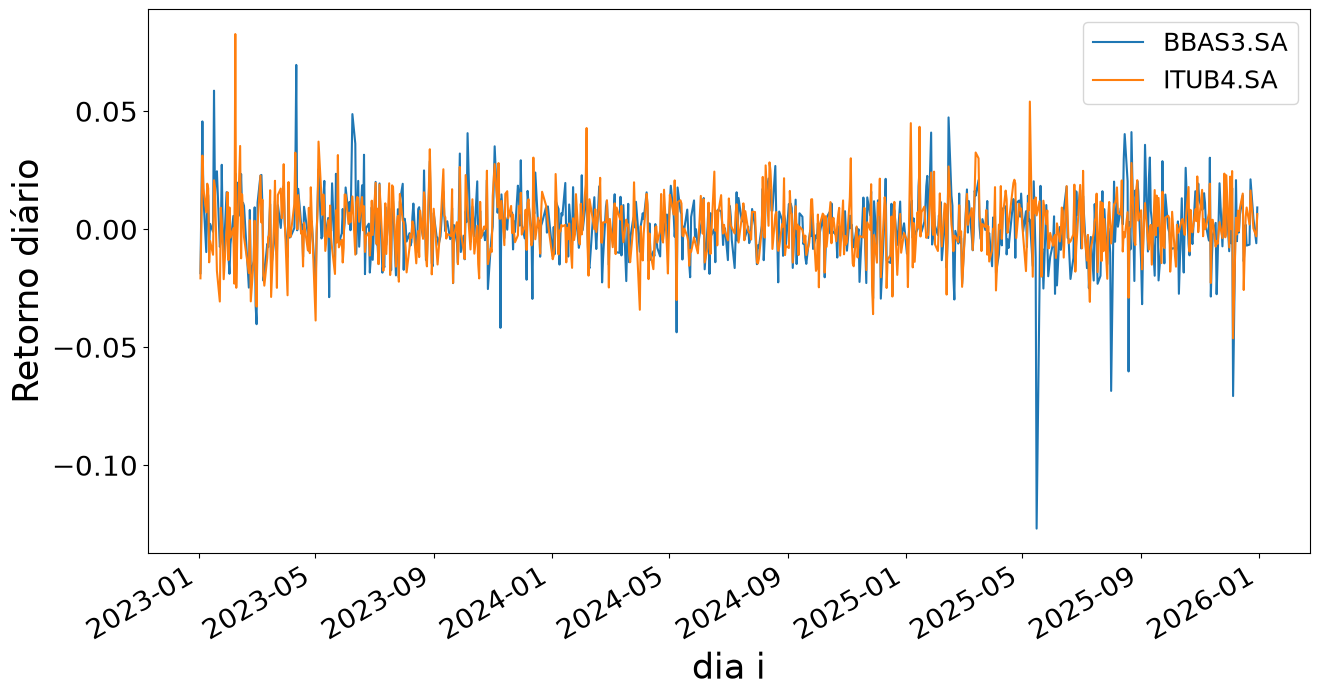

In [69]:
#Plot do retorno diário dos n primeiros ativos
n = 2
retorno[ativos[0:n]].plot(figsize=[15,8]) #n ativos
plt.xlabel('dia i',  fontsize=25)
plt.ylabel('Retorno diário',fontsize=25)
plt.xticks(fontsize=20)
plt.yticks(fontsize=20)
plt.legend(loc = 'best', fontsize=18);
plt.show()

In [70]:
log_retorno = np.log(df/df.shift())
#log_retorno = df.pct_change().apply(lambda x: np.log(1+x))
log_retorno

Ticker,BBAS3.SA,ITUB4.SA,KLBN4.SA,VALE3.SA
Date,,,,
2023-01-02,NaN,NaN,NaN,NaN
2023-01-03,-0.018817,-0.021044,0.004975,-0.001791
2023-01-04,0.012786,0.002915,0.012331,0.001791
2023-01-05,0.044662,0.030709,0.007326,0.016639
2023-01-06,0.013789,0.017190,-0.009780,0.015717
...,...,...,...,...
2025-12-22,-0.006551,0.002022,0.016217,0.028798
2025-12-23,0.020907,0.016277,0.002677,-0.000274
2025-12-26,0.004587,0.000323,0.000000,0.003013


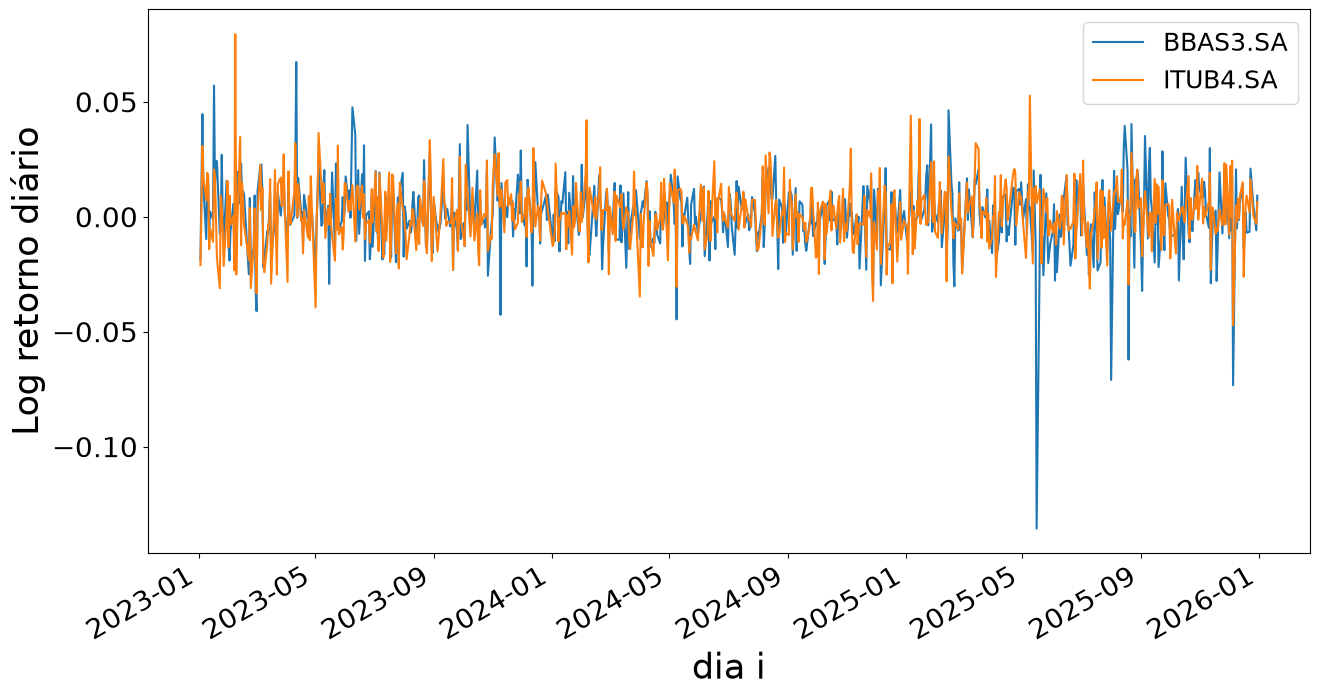

In [71]:
n = 2
log_retorno[ativos[0:n]].plot(figsize=[15,8]) #n ativos
plt.xlabel('dia i',  fontsize=25)
plt.ylabel('Log retorno diário',fontsize=25)
plt.xticks(fontsize=20)
plt.yticks(fontsize=20)
plt.legend(loc = 'best', fontsize=18);
plt.show()

## 4. Risco: variância

**Pergunta:** o quanto a ação balança em torno da média?

## Cálculo da variância

A variância dos retornos das ações de uma empresa é um indicador importante de quão volátil esse investimento será, ou seja, como os retornos podem flutuar.

$$
\sigma^2 =  \frac{1}{N-1} \sum_{i = 1}^N (R_i - \mu)^2
$$

Onde $R_i$ é o retorno do dia i e $\mu$ é o retorno esperado (retorno médio).

In [72]:
variancia = retorno.var()
variancia

Ticker
BBAS3.SA    0.000220
ITUB4.SA    0.000173
KLBN4.SA    0.000173
VALE3.SA    0.000228
dtype: float64

## 4.1 Volatilidade

**Pergunta:** qual é o risco na escala anual, em porcentagem?

## Cálculo de volatilidade

É o desvio padrão das ações de uma empresa, ou seja, como os retornos podem flutuar. A volatilidade é a raiz quadrada da variância.

$$
\sigma = \sqrt{  \frac{1}{N-1} \sum_{i = 1}^N (R_i - \mu)^2 }
$$

In [73]:
volatld = np.sqrt(variancia * 252) # 252 dias úteis (B3). Para criptomoedas use 365, pois as negociações ocorrem todo dia.
volatld

Ticker
BBAS3.SA    0.235502
ITUB4.SA    0.208856
KLBN4.SA    0.208632
VALE3.SA    0.239544
dtype: float64

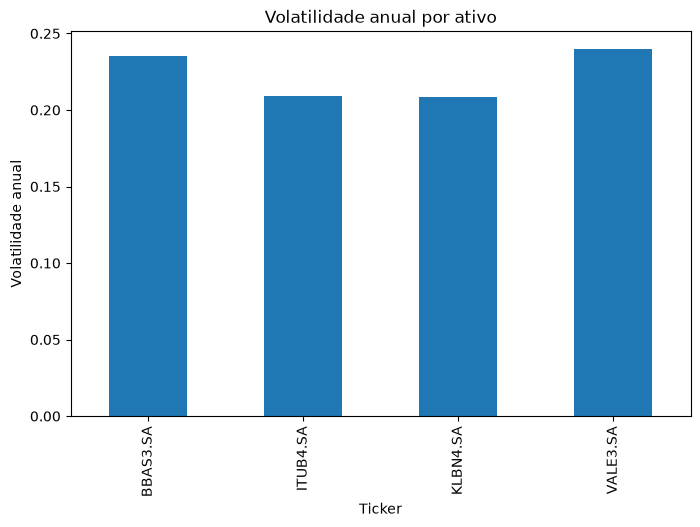

In [74]:
ax = volatld.plot(kind='bar', figsize=[8,5], title='Volatilidade anual por ativo')
ax.set_ylabel('Volatilidade anual')
plt.show()

## 5. Covariância

**Pergunta:** dois ativos andam juntos ou em sentidos opostos?

## Covariância

Covariância é uma medida estatística que indica a relação direcional entre duas variáveis, no nosso caso, entre os retornos de dois ativos. A covariância pode ser positiva, negativa ou nula.

Significa que, se a covariância for positiva, os retornos dos ativos tendem a se mover na mesma direção. Se for negativa, os retornos tendem a se mover em direções opostas. E se for nula, não há relação linear entre os retornos dos ativos.

Uma covariância positiva significa que os retornos dos dois ativos se movem juntos (ambos caem ou sobem), enquanto uma covariância negativa significa que eles se movem inversamente (quando um sobe ou outro tende a cair e vice versa). O risco (assumido como a volatilidade) pode ser reduzido em uma carteira combinando ativos que têm uma covariância negativa.

In [75]:
# Matriz covariante
#cov_matrix = df.pct_change().apply(lambda x: np.log(1+x)).cov() # Log of percentage change
cov_matrix = df.pct_change().cov() # Sem log of percentage change
cov_matrix
     

Ticker,BBAS3.SA,ITUB4.SA,KLBN4.SA,VALE3.SA
Ticker,,,,
BBAS3.SA,0.000220,0.000105,0.000035,0.000028
ITUB4.SA,0.000105,0.000173,0.000028,0.000042
KLBN4.SA,0.000035,0.000028,0.000173,0.000051
VALE3.SA,0.000028,0.000042,0.000051,0.000228


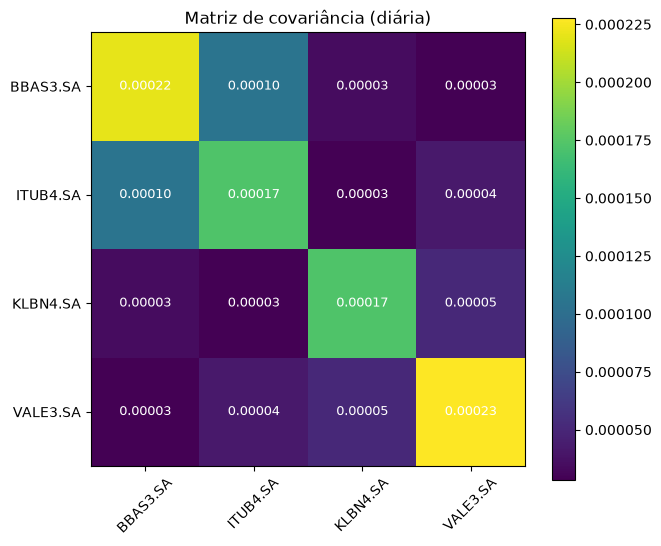

In [76]:
# Matriz de covariância (diária) com rótulos e valores
fig, ax = plt.subplots(figsize=[7,6])
im = ax.imshow(cov_matrix.values, cmap='viridis')
ax.set_xticks(range(len(cov_matrix))); ax.set_xticklabels(cov_matrix.columns, rotation=45)
ax.set_yticks(range(len(cov_matrix))); ax.set_yticklabels(cov_matrix.index)
for i in range(len(cov_matrix)):
    for j in range(len(cov_matrix)):
        ax.text(j, i, f'{cov_matrix.iloc[i, j]:.5f}', ha='center', va='center', color='w', fontsize=9)
fig.colorbar(im, ax=ax)
ax.set_title('Matriz de covariância (diária)')
plt.show()

## 5.1 Correlação

**Pergunta:** qual é essa relação, numa escala de −1 a +1?

## Correlação

A correlação, nos setores de finanças e investimento, é uma estatística que mede o grau em que dois títulos se movem em relação um ao outro. As correlações são usadas no gerenciamento avançado de portfólio, calculado como o coeficiente de correlação, que tem um valor entre -1 e +1. A correlação é uma versão normalizada da covariância.

In [77]:
# Matriz de correlação
#corr_matrix = df.pct_change().apply(lambda x: np.log(1+x)).corr()
corr_matrix = df.pct_change().corr()
corr_matrix

Ticker,BBAS3.SA,ITUB4.SA,KLBN4.SA,VALE3.SA
Ticker,,,,
BBAS3.SA,1.000000,0.537551,0.177441,0.126197
ITUB4.SA,0.537551,1.000000,0.164054,0.211842
KLBN4.SA,0.177441,0.164054,1.000000,0.257288
VALE3.SA,0.126197,0.211842,0.257288,1.000000


## 6. Pesos e portfólios

**Pergunta:** quanto colocar em cada ativo?

# Pesos

Na abordagem clássica de Markowitz, os pesos é a alocação percentual dos investimentos entre os ativos de um portfólio. A soma dos pesos deve ser sempre igual a 1 ou 100%.

Abaixo sorteamos pesos aleatórios apenas para ilustrar a nuvem de carteiras. A fronteira eficiente é calculada por otimização, mais adiante.

Portanto, o problema de otimização é encontrar os pesos $w$ que minimizam a variância (e, portanto, a volatilidade) para cada nível de retorno-alvo. O conjunto dessas carteiras ótimas é a fronteira eficiente.

In [78]:
n_atv = len(ativos)             # Número de ativos
pesos = np.random.random(n_atv) # Escolhendo pesos aleatórios para cada ativo
pesos = pesos/np.sum(pesos)     # Promovendo a normalização
print('ativos: ',ativos)        # Símbolo dos ativos
print('pesos : ',pesos)         # Array de pesos aleatórios

ativos:  ['BBAS3.SA', 'ITUB4.SA', 'KLBN4.SA', 'VALE3.SA']
pesos :  [0.39815192 0.29097484 0.05316882 0.25770442]


## 7. Índice de Sharpe

**Pergunta:** qual carteira entrega mais retorno por unidade de risco?

## Sharpe Ratio (SR)

Esse índice é o retorno médio obtido em excesso da taxa livre de risco por unidade de volatilidade ou risco total. Como já visto, a volatilidade é uma medida das flutuações de preço de um ativo ou portfólio.

A taxa de retorno livre de risco é o retorno de um investimento com risco zero, o que significa que é o retorno que os investidores poderiam esperar por não correr risco.

A carteira de risco ideal é aquela com o maior Sharpe Ratio. Essa conclusão vale sob a premissa de que o investidor pode emprestar e tomar emprestado à taxa livre de risco; sem essa premissa, o maior Sharpe é apenas a melhor relação risco-retorno entre as carteiras analisadas.

$SR = \frac{R_p - R_f}{\sigma_p},$

Onde:
- $R_p$: Retorno esperado do portfólio
- $R_f$: Retorno da taxa livre de risco
- $\sigma_p$: Desvio padrão (volatilidade) do portfólio

No código abaixo usamos uma única taxa livre de risco, o CDI médio do período dos dados (2023-2025). O IPCA não entra aqui, pois mede inflação e não retorno sem risco.

## 8. Otimização clássica

**Pergunta:** quais carteiras formam a fronteira eficiente?

## Otimização Clássica Irrestrita

Escolhido ativos nos passos anteriores, os ingredientes essenciais da abordagem clássica: o retorno anual e a volatilidade. Na sequência, geraremos vários portfólios (pesos), dos quais calculamos o retorno e a volatilidade que pretendemos otimizar.

In [79]:
# Retorno esperado anual: média dos retornos diários x 252 dias úteis.
# Usa todas as observações (não só os fechamentos anuais).
ind_er = retorno.mean() * 252
ind_er

Ticker
BBAS3.SA    0.192398
ITUB4.SA    0.304509
KLBN4.SA    0.108964
VALE3.SA    0.054557
dtype: float64

In [80]:
# Volatilidade 
# A volatilidade é dada pelo desvio padrão anual. Multiplicamos a volatilidade diária por 252 (dias úteis / ano).
# Use 365 ao invés de 252 para criptomoedas
#ann_sd = df.pct_change().apply(lambda x: np.log(1+x)).std().apply(lambda x: x*np.sqrt(252))
ann_sd = df.pct_change().std().apply(lambda x: x*np.sqrt(252))
ann_sd

Ticker
BBAS3.SA    0.235502
ITUB4.SA    0.208856
KLBN4.SA    0.208632
VALE3.SA    0.239544
dtype: float64

In [81]:
assets = pd.concat([ind_er, ann_sd], axis=1) # Criando um DataFrame com retornos e volatilidade dos portfólios
assets.columns = ['Retorno', 'Risco']
assets

,Retorno,Risco
Ticker,,
BBAS3.SA,0.192398,0.235502
ITUB4.SA,0.304509,0.208856
KLBN4.SA,0.108964,0.208632
VALE3.SA,0.054557,0.239544


In [82]:
p_ret    = [] # Define uma "empty list" para os retornos dos portfólios
p_vol    = [] # Define uma "empty list" para a volatilidade dos portfólios
p_pesos  = [] # Define uma "empty list" para os pesos dos ativos no portfólio

np.random.seed(42)  # sementes fixas para reprodutibilidade (E-16)
num_portfolios = 2000

In [83]:
for port in range(num_portfolios):
    pesos = np.random.dirichlet(np.ones(n_atv))  # pesos aleatórios que somam 1 (E-05)
    p_pesos.append(pesos)
    retornos = np.dot(pesos, ind_er)      #Retornos: produto entre os retornos esperados individuais dos ativos e seus pesos 
    p_ret.append(retornos)
    var_port = pesos @ cov_matrix.values @ pesos  # Variância do portfólio (forma matricial)
    sd_port  = np.sqrt(var_port)          #Desvio padrão diário
    vol_port = sd_port*np.sqrt(252)       #Desvio padrão anual == volatilidade
    p_vol.append(vol_port)

In [84]:
data = {'Retorno':p_ret, 'Risco':p_vol}

for counter, symbol in enumerate(df.columns.tolist()):
    #print(counter, symbol)
    data['peso '+ symbol] = [w[counter] for w in p_pesos]

In [85]:
portfolios  = pd.DataFrame(data)
portfolios.head(n = 10) # Visualizar os n primeiros portfólio dos 2000 portfólios criados com pesos aleatórios

,Retorno,Risco,peso BBAS3.SA,peso ITUB4.SA,peso KLBN4.SA,peso VALE3.SA
0,0.210223,0.153517,0.082197,0.527252,0.230641,0.159911
1,0.083196,0.208331,0.070375,0.070363,0.024826,0.834435
2,0.131314,0.177717,0.161962,0.216972,0.003665,0.617401
3,0.185022,0.193278,0.735638,0.098290,0.082638,0.083434
4,0.186828,0.147310,0.179898,0.368931,0.280463,0.170708
5,0.152955,0.160999,0.498510,0.079138,0.182004,0.240349
6,0.209965,0.160601,0.196962,0.497451,0.072045,0.233543
7,0.144764,0.160037,0.434130,0.023007,0.452428,0.090435
8,0.170622,0.149015,0.008341,0.368765,0.417989,0.204904
9,0.117535,0.155796,0.165213,0.046740,0.524238,0.263809


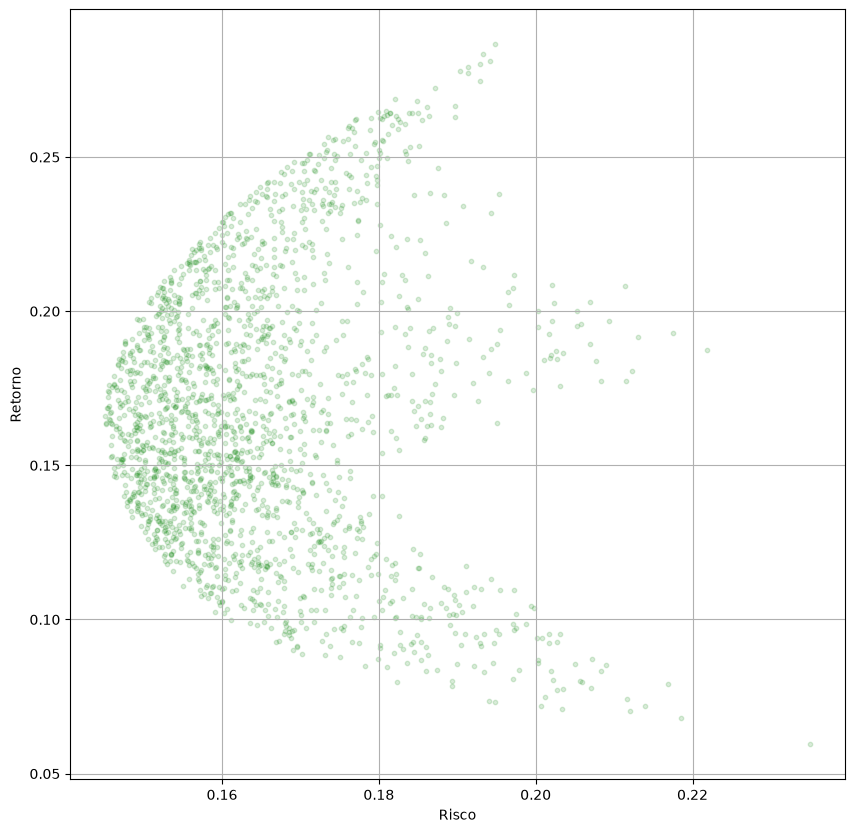

In [86]:
# Nuvem de carteiras aleatórias (apenas ilustração). A fronteira eficiente real é calculada por otimização na célula seguinte (E-05).
portfolios.plot.scatter(x='Risco', y='Retorno', c='green', marker='o', s=10, alpha=0.15, grid=True, figsize=[10,10]);

In [87]:
min_vol_port = portfolios.iloc[portfolios['Risco'].idxmin()]
# idxmin() retorna o valor mínimo na coluna especificada                         
min_vol_port

Retorno          0.165934
Risco            0.145125
peso BBAS3.SA    0.174990
peso ITUB4.SA    0.276248
peso KLBN4.SA    0.334654
peso VALE3.SA    0.214108
Name: 458, dtype: float64

In [88]:
max_ret_port = portfolios.iloc[portfolios['Retorno'].idxmax()]
# idxmax() retorna o valor máximo na coluna especificada                         
max_ret_port

Retorno          0.286507
Risco            0.194868
peso BBAS3.SA    0.028861
peso ITUB4.SA    0.900045
peso KLBN4.SA    0.055198
peso VALE3.SA    0.015896
Name: 947, dtype: float64

In [89]:
# Portfólio ótimo (melhor Sharpe Ratio) com UMA taxa livre de risco.
# rf = CDI médio aproximado no período 2023-2025. Conferir na série SGS 12 do BCB antes de fixar.
rf = 0.13
opt_sharpe = portfolios.iloc[((portfolios['Retorno'] - rf) / portfolios['Risco']).idxmax()]
opt_sharpe

Retorno          0.286507
Risco            0.194868
peso BBAS3.SA    0.028861
peso ITUB4.SA    0.900045
peso KLBN4.SA    0.055198
peso VALE3.SA    0.015896
Name: 947, dtype: float64

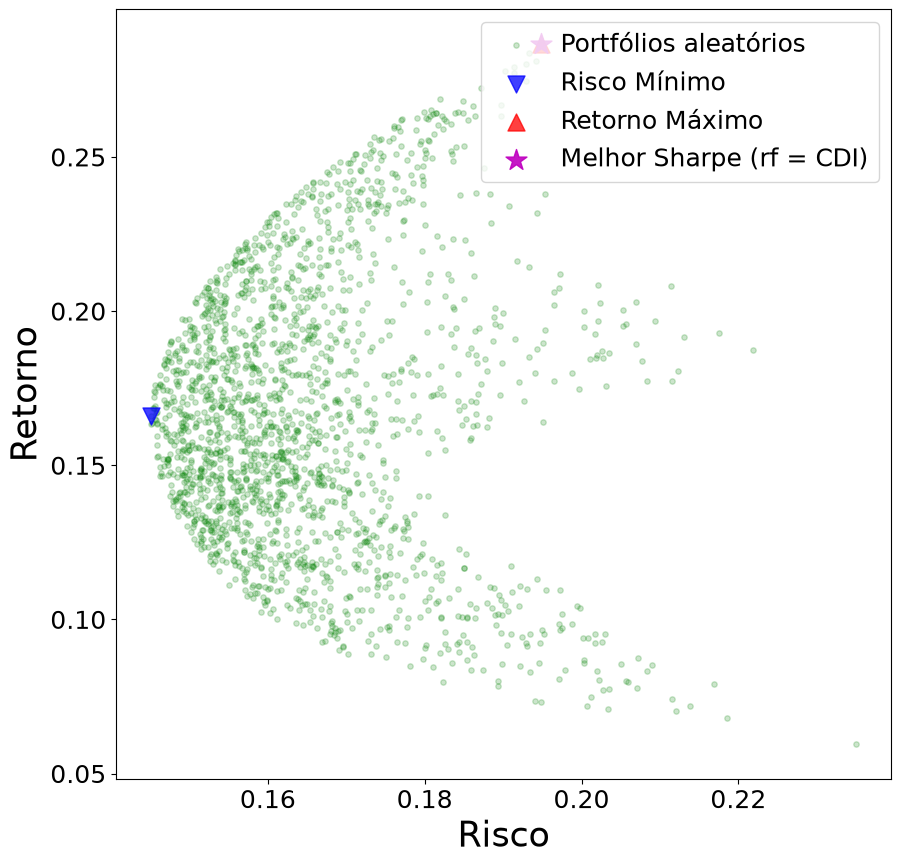

In [90]:
# Plotando o portfólio com volatilidade mínima, retorno máximo e melhor Sharpe
plt.subplots(figsize=[10,10])
plt.scatter(portfolios['Risco'], portfolios['Retorno'], c='g', marker='o', s=15, alpha=0.2, label='Portfólios aleatórios')
plt.scatter(min_vol_port['Risco'], min_vol_port['Retorno'], c='b', marker='v', s=150, alpha=0.75, label='Risco Mínimo')
plt.scatter(max_ret_port['Risco'], max_ret_port['Retorno'], c='r', marker='^', s=150, alpha=0.75, label='Retorno Máximo')
plt.scatter(opt_sharpe['Risco'], opt_sharpe['Retorno'], c='m', marker='*', s=250, alpha=0.9, label='Melhor Sharpe (rf = CDI)')
plt.xlabel('Risco', fontsize=25)
plt.ylabel('Retorno', fontsize=25)
plt.xticks(fontsize=18)
plt.yticks(fontsize=18)
plt.legend(loc='best', fontsize=18);

In [91]:
# Fronteira eficiente por otimização (E-03).
# Para cada retorno-alvo, minimiza a variância w'Σw sujeito a sum(w)=1, w>=0 e w'μ = alvo.
# Σ é anualizada (cov diária x 252) para ficar na mesma escala de μ.
from scipy.optimize import minimize

cov_anual = cov_matrix.values * 252
mu = ind_er.values
n_ativos = len(mu)

alvos = np.linspace(mu.min(), mu.max(), 60)
x_new, y_new = [], []   # x_new: risco (volatilidade anual); y_new: retorno-alvo
for alvo in alvos:
    restricoes = (
        {'type': 'eq', 'fun': lambda w: w.sum() - 1},
        {'type': 'eq', 'fun': lambda w, a=alvo: w @ mu - a},
    )
    res = minimize(lambda w: w @ cov_anual @ w, np.full(n_ativos, 1 / n_ativos),
                   bounds=[(0, 1)] * n_ativos, constraints=restricoes, method='SLSQP')
    if res.success:
        x_new.append(np.sqrt(res.x @ cov_anual @ res.x))
        y_new.append(alvo)
x_new, y_new = np.array(x_new), np.array(y_new)
print(f'Pontos da fronteira: {len(x_new)} (de {len(alvos)} alvos)')

Pontos da fronteira: 60 (de 60 alvos)


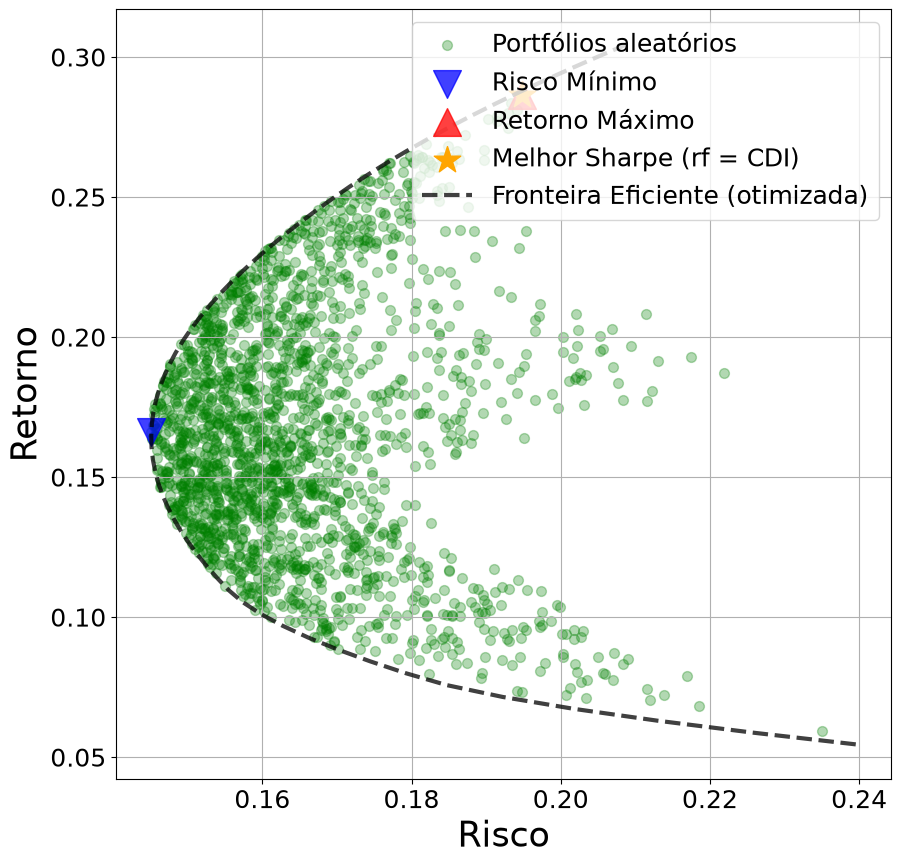

In [92]:
# Plotando a nuvem aleatória, a fronteira eficiente e os portfólios de referência
plt.subplots(figsize=[10,10])
plt.scatter(portfolios['Risco'], portfolios['Retorno'], c='g', marker='o', s=50, alpha=0.3, label='Portfólios aleatórios')
plt.scatter(min_vol_port['Risco'], min_vol_port['Retorno'], c='b', marker='v', s=400, alpha=0.75, label='Risco Mínimo')
plt.scatter(max_ret_port['Risco'], max_ret_port['Retorno'], c='r', marker='^', s=400, alpha=0.75, label='Retorno Máximo')
plt.scatter(opt_sharpe['Risco'], opt_sharpe['Retorno'], c='orange', marker='*', s=400, alpha=1, label='Melhor Sharpe (rf = CDI)')
plt.plot(x_new, y_new, '--', c='k', linewidth=3, alpha=0.75, label='Fronteira Eficiente (otimizada)')
plt.xlabel('Risco', fontsize=25)
plt.ylabel('Retorno', fontsize=25)
plt.xticks(fontsize=18)
plt.yticks(fontsize=18)
plt.grid()
plt.legend(loc='best', fontsize=18);

## 9. Teste fora da amostra

**Pergunta:** a carteira otimizada com dados passados funciona em dados novos?

## Teste fora da amostra

Até aqui otimizamos e avaliamos no mesmo período, o que mostra apenas o ajuste ao passado. Abaixo, a carteira é otimizada com dados de 2023–2024 e avaliada em 2025, e comparada com a carteira de pesos iguais, que não depende de estimar retornos.

Se a carteira otimizada vence no treino e perde no teste, ela estava ajustando ruído.

In [93]:
# Teste fora da amostra (E-07)
from scipy.optimize import minimize

rf = 0.13  # mesma taxa da seção de Sharpe (conferir no BCB)
ret_treino = retorno.loc[:'2024-12-31'].dropna()
ret_teste  = retorno.loc['2025-01-01':].dropna()

mu_tr  = ret_treino.mean().values * 252
cov_tr = ret_treino.cov().values * 252
n = len(mu_tr)

def neg_sharpe(w):
    return -((w @ mu_tr - rf) / np.sqrt(w @ cov_tr @ w))

res = minimize(neg_sharpe, np.full(n, 1 / n), bounds=[(0, 1)] * n,
               constraints=({'type': 'eq', 'fun': lambda w: w.sum() - 1},), method='SLSQP')
assert res.success, res.message
w_opt = res.x
w_eq = np.full(n, 1 / n)

def metricas(w, ret):
    r = ret.values @ w
    ret_anual = r.mean() * 252
    vol_anual = r.std(ddof=1) * np.sqrt(252)
    return ret_anual, vol_anual, (ret_anual - rf) / vol_anual

print('Pesos da carteira otimizada no treino:')
print(pd.Series(w_opt, index=ret_teste.columns).round(3))

linhas = []
for nome, w in [('Pesos iguais', w_eq), ('Máximo Sharpe (otimizada no treino)', w_opt)]:
    r_anual, v_anual, sh = metricas(w, ret_teste)
    linhas.append({'Carteira': nome, 'Retorno 2025': r_anual, 'Risco 2025': v_anual, 'Sharpe 2025': sh})
pd.DataFrame(linhas).set_index('Carteira').round(3)

Pesos da carteira otimizada no treino:
Ticker
BBAS3.SA    0.77
ITUB4.SA    0.00
KLBN4.SA    0.23
VALE3.SA    0.00
dtype: float64


,Retorno 2025,Risco 2025,Sharpe 2025
Carteira,,,
Pesos iguais,0.215,0.152,0.558
Máximo Sharpe (otimizada no treino),-0.027,0.229,-0.685


## 10. Distribuição dos retornos

**Pergunta:** os retornos seguem uma curva normal, como o modelo assume?

## Distribuição dos retornos

Markowitz assume retornos aproximadamente normais. Vale checar: se a curtose em excesso for alta, há eventos extremos mais frequentes do que a normal prevê, e a variância subestima esse risco.

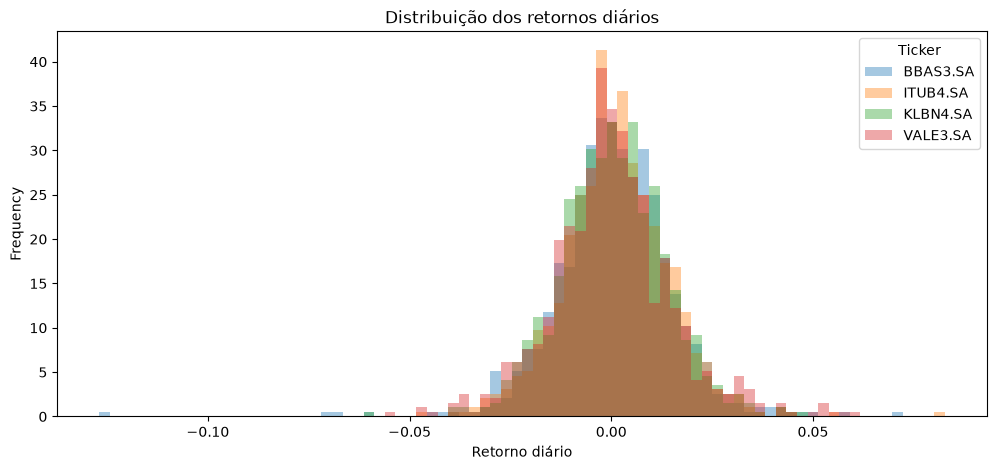

Curtose em excesso (0 = normal):
Ticker
BBAS3.SA    9.34
ITUB4.SA    2.45
KLBN4.SA    0.83
VALE3.SA    1.66
dtype: float64


In [94]:
# Distribuição dos retornos diários
r = retorno.dropna()
ax = r.plot.hist(bins=80, alpha=0.4, density=True, figsize=[12,5])
ax.set_xlabel('Retorno diário')
ax.set_title('Distribuição dos retornos diários')
plt.show()
print('Curtose em excesso (0 = normal):')
print(r.kurtosis().round(2))